In [16]:
#pip install kagglehub[pandas-datasets]

In [17]:
import pandas as pd





# Load the latest version
df = pd.read_csv("F:/Descargas/amz_uk_price_prediction_dataset.csv")
print("First 5 records:", df.head())


First 5 records:    uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  


In [18]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


# Part 1: Understanding Product Categories

In [5]:
print(df.columns)

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')


In [6]:
# Frequency table for product category
category_freq = df['category'].value_counts().reset_index()

# Rename columns for clarity
category_freq.columns = ['category', 'count']

# Display the frequency table
print(category_freq.head())

                                 category   count
0                       Sports & Outdoors  836265
1                                  Beauty   19312
2  Handmade Clothing, Shoes & Accessories   19229
3                             Bath & Body   19092
4                          Birthday Gifts   18978


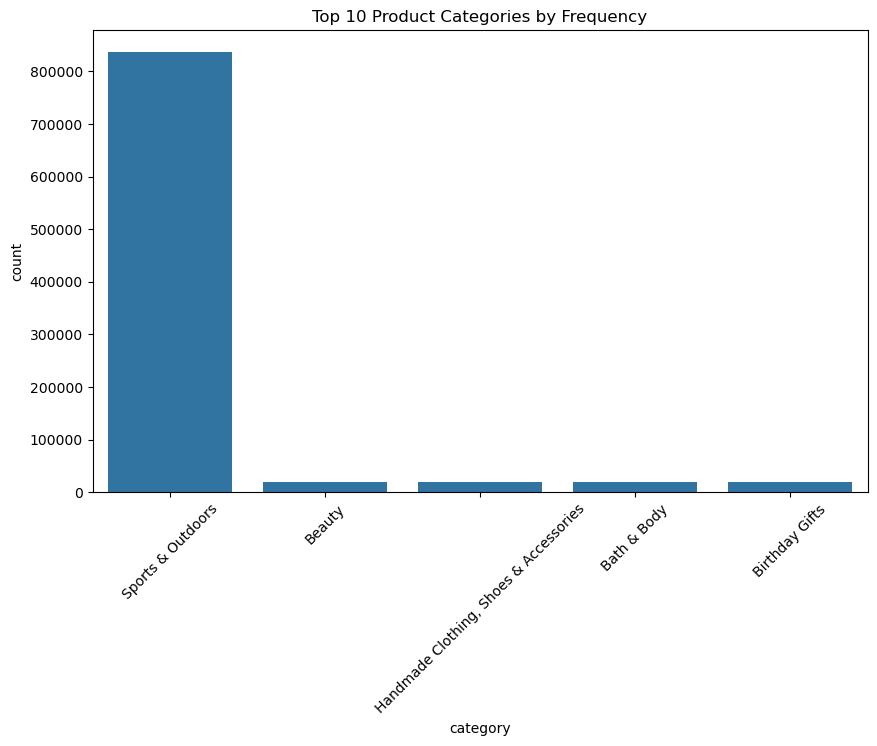

Text(0.5, 1.0, 'Top 10 Product Categories by Frequency')

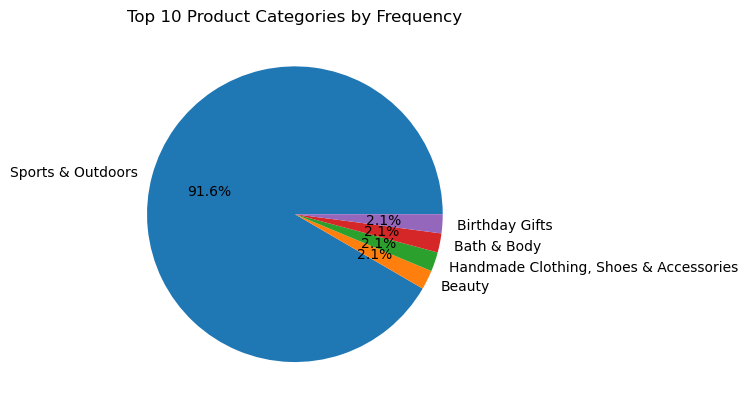

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
# Bar plot for product category distribution
plt.figure(figsize=(10, 6))
sns.barplot(data=category_freq.head(5), x='category', y='count')
plt.xticks(rotation=45)
plt.title('Top 10 Product Categories by Frequency')
plt.show()
# Pie chart for product category distribution

plt.pie(category_freq['count'].head(5), labels=category_freq['category'].head(5), autopct='%1.1f%%')
plt.title('Top 10 Product Categories by Frequency')
 
 # Sports & Outdoors dominates the category distribution


# Part 2: Delving into Product Pricing

In [26]:
mean_price = df['price'].mean()
mode_price = df['price'].mode()[0]
median_price = df['price'].median()
print(f"Average Price (Mean): {mean_price:.2f}")
print(f"Most Common Price (Mode): {mode_price:.2f}")
print(f"Middle Price (Median): {median_price:.2f}")

Average Price (Mean): 89.24
Most Common Price (Mode): 9.99
Middle Price (Median): 19.09


In [27]:
var_price = df['price'].var()
std = df['price'].std()
rng = df['price'].max() - df['price'].min()
interquartile_range = df['price'].quantile(0.75) - df['price'].quantile(0.25)
print(f"Price Variance: {var_price:.2f}")
print(f"Price Standard Deviation: {std:.2f}")
print(f"Price Range: {rng:.2f}")
print(f"Interquartile Range (IQR): {interquartile_range:.2f}")

Price Variance: 119445.49
Price Standard Deviation: 345.61
Price Range: 100000.00
Interquartile Range (IQR): 36.00


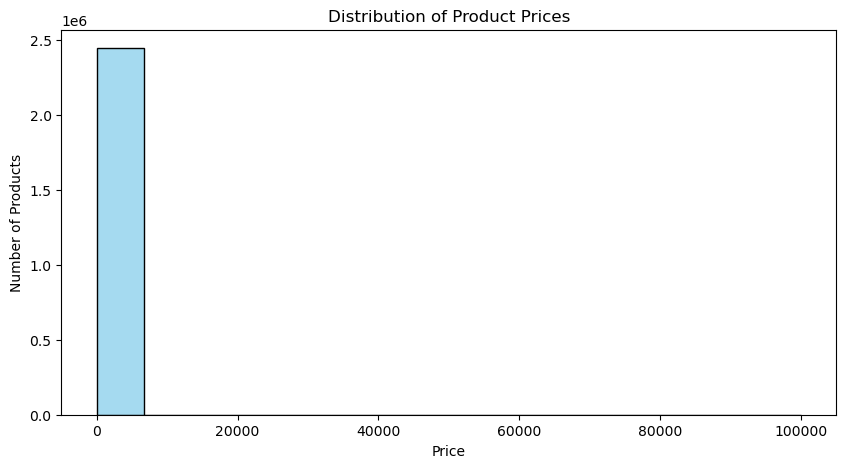

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(df['price'], bins=15, kde=False, color="skyblue", edgecolor="black")
plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Number of Products")
plt.show()

# The probability distribution of product prices is right-skewed, with most products priced below 100. A few high-priced items create a long tail on the right side of the distribution. 
#Could be solved excluding outliers or applying a log transformation.


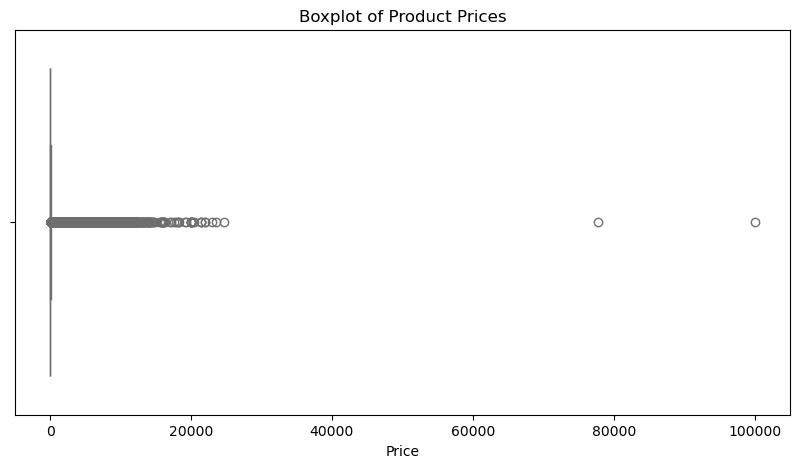

In [31]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['price'], color="skyblue")
plt.title("Boxplot of Product Prices")
plt.xlabel("Price")
plt.show()

# Part 3: Unpacking Product Ratings

In [33]:
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]
print(f"Average Rating (Mean): {mean_rating:.2f}")
print(f"Middle Rating (Median): {median_rating:.2f}")
print(f"Most Common Rating (Mode): {mode_rating:.2f}")

Average Rating (Mean): 2.15
Middle Rating (Median): 0.00
Most Common Rating (Mode): 0.00


In [34]:
var_rating = df['stars'].var()
std_rating = df['stars'].std()
rng_rating = df['stars'].max() - df['stars'].min()
interquartile_range_rating = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)
print(f"Rating Variance: {var_rating:.2f}")
print(f"Rating Standard Deviation: {std_rating:.2f}")
print(f"Rating Range: {rng_rating:.2f}")
print(f"Interquartile Range (IQR): {interquartile_range_rating:.2f}")


Rating Variance: 4.82
Rating Standard Deviation: 2.19
Rating Range: 5.00
Interquartile Range (IQR): 4.40


In [36]:
from scipy.stats import skew, kurtosis

skewness = skew(df['stars'])
kurt = kurtosis(df['stars'])

print(f"Skewness: {skewness:.4f}")
print(f"Kurtosis: {kurt:.4f}")

Skewness: 0.0812
Kurtosis: -1.9260


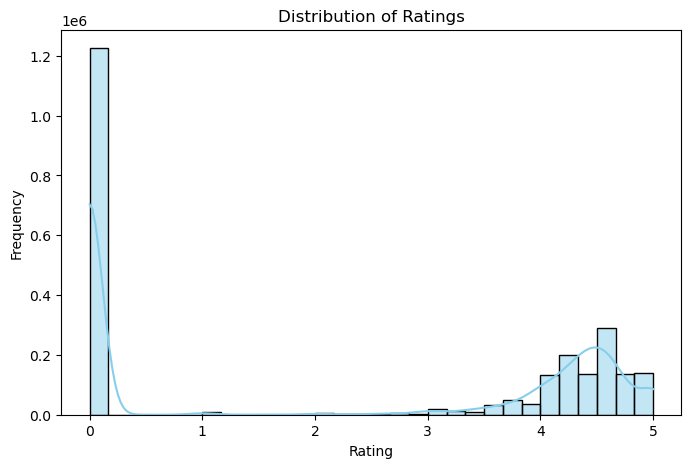

In [37]:
plt.figure(figsize=(8,5))
sns.histplot(df['stars'], bins=30, kde=True, color='skyblue')
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()